In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import files
import io
uploaded = files.upload()

df = pd.read_csv(io.BytesIO(uploaded[next(iter(uploaded))]))

df.head()

Saving covid_19_clean_complete.csv to covid_19_clean_complete.csv


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [4]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

df.info()
df.describe()

Shape: (49068, 10)

Columns:
Index(['Province/State', 'Country/Region', 'Lat', 'Long', 'Date', 'Confirmed',
       'Deaths', 'Recovered', 'Active', 'WHO Region'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


,Lat,Long,Confirmed,Deaths,Recovered,Active
count,49068.000000,49068.000000,4.906800e+04,49068.000000,4.906800e+04,4.906800e+04
mean,21.433730,23.528236,1.688490e+04,884.179160,7.915713e+03,8.085012e+03
std,24.950320,70.442740,1.273002e+05,6313.584411,5.480092e+04,7.625890e+04
min,-51.796300,-135.000000,0.000000e+00,0.000000,0.000000e+00,-1.400000e+01
25%,7.873054,-15.310100,4.000000e+00,0.000000,0.000000e+00,0.000000e+00
50%,23.634500,21.745300,1.680000e+02,2.000000,2.900000e+01,2.600000e+01
75%,41.204380,80.771797,1.518250e+03,30.000000,6.660000e+02,6.060000e+02
max,71.706900,178.065000,4.290259e+06,148011.000000,1.846641e+06,2.816444e+06


In [5]:
# Check missing values
df.isnull().sum()

# Convert Date column
df['Date'] = pd.to_datetime(df['Date'])

# Check duplicates
print("Duplicates:", df.duplicated().sum())

# Fill missing numerical values
numeric_cols = ['Confirmed', 'Deaths', 'Recovered', 'Active']

df[numeric_cols] = df[numeric_cols].fillna(0)

df.head()

Duplicates: 0


,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


In [6]:
daily = df.groupby('Date')[['Confirmed', 'Deaths', 'Recovered', 'Active']].sum()

daily.head()

,Confirmed,Deaths,Recovered,Active
Date,,,,
2020-01-22,555,17,28,510
2020-01-23,654,18,30,606
2020-01-24,941,26,36,879
2020-01-25,1434,42,39,1353
2020-01-26,2118,56,52,2010


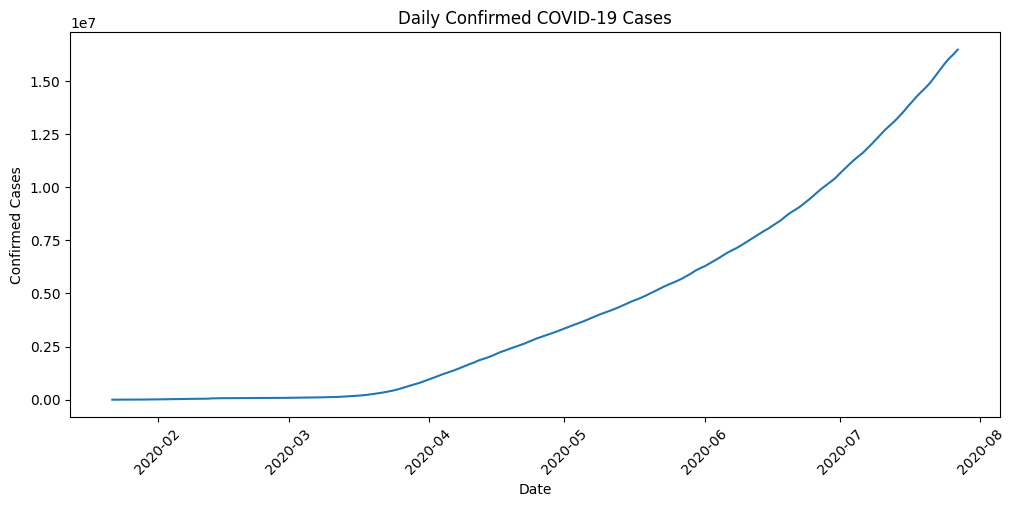

In [7]:
plt.figure(figsize=(12,5))
plt.plot(daily.index, daily['Confirmed'])
plt.title("Daily Confirmed COVID-19 Cases")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.show()

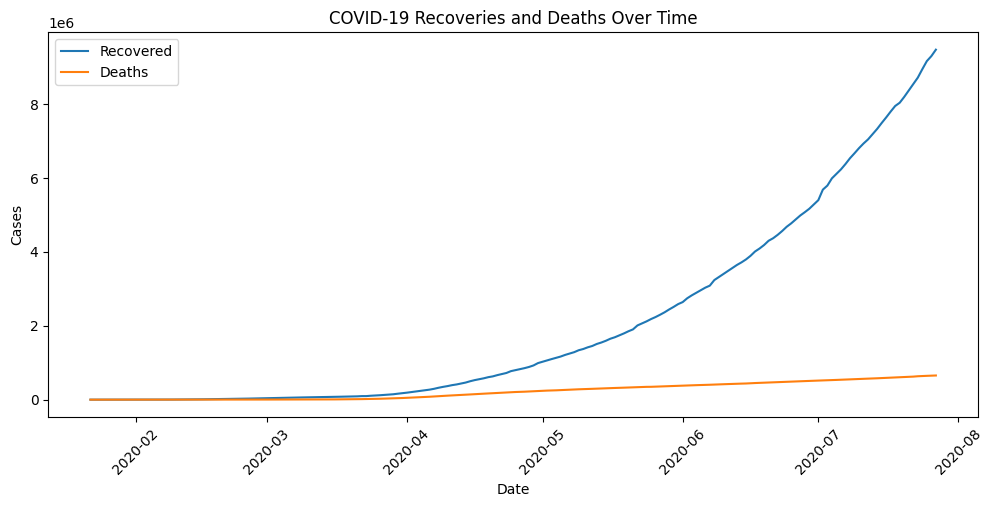

In [8]:
plt.figure(figsize=(12,5))

plt.plot(daily.index, daily['Recovered'], label='Recovered')
plt.plot(daily.index, daily['Deaths'], label='Deaths')

plt.title("COVID-19 Recoveries and Deaths Over Time")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.xticks(rotation=45)
plt.show()

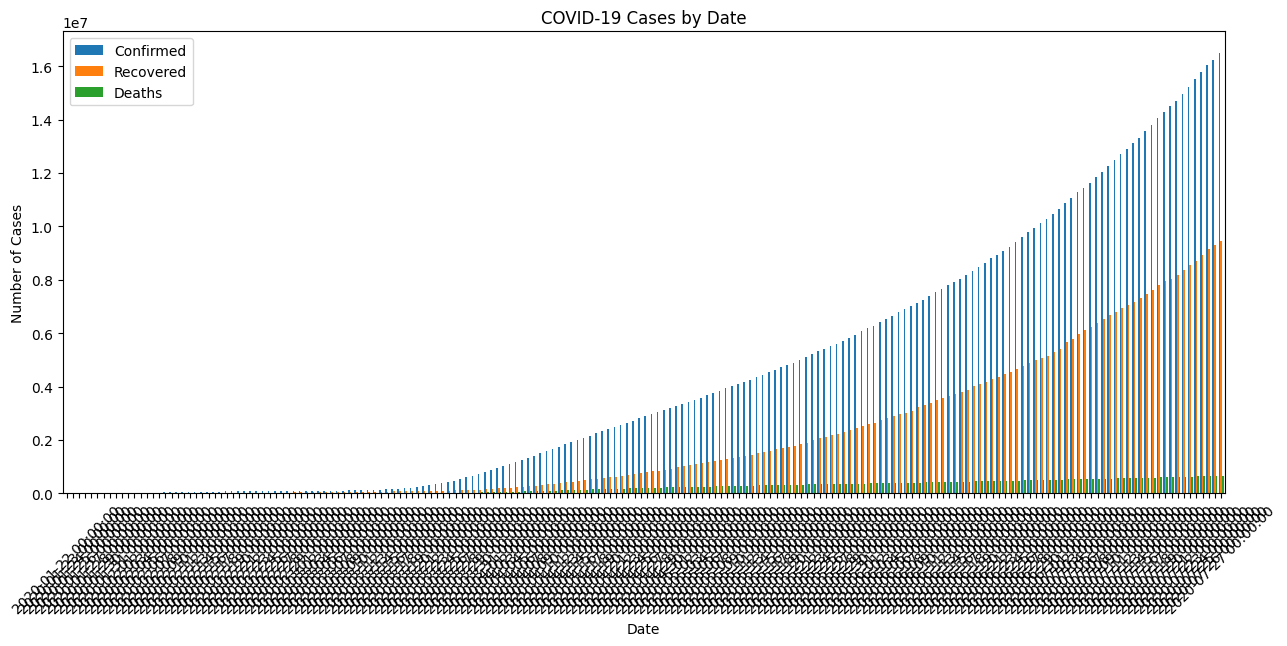

In [9]:
daily[['Confirmed', 'Recovered', 'Deaths']].plot(
    kind='bar',
    figsize=(15,6),
    width=0.8
)

plt.title("COVID-19 Cases by Date")
plt.xlabel("Date")
plt.ylabel("Number of Cases")
plt.xticks(rotation=45)
plt.show()

In [10]:
country_data = df.groupby('Country/Region')[
    ['Confirmed', 'Deaths', 'Recovered', 'Active']
].max()

country_data = country_data.sort_values(
    'Confirmed',
    ascending=False
)

country_data.head(10)

,Confirmed,Deaths,Recovered,Active
Country/Region,,,,
US,4290259,148011,1325804,2816444
Brazil,2442375,87618,1846641,583080
India,1480073,33408,951166,495499
Russia,816680,13334,602249,245382
South Africa,452529,7067,274925,173590
Mexico,395489,44022,303810,53572
Peru,389717,18418,272547,108616
Chile,347923,9187,319954,82961
United Kingdom,300111,45759,533,254352


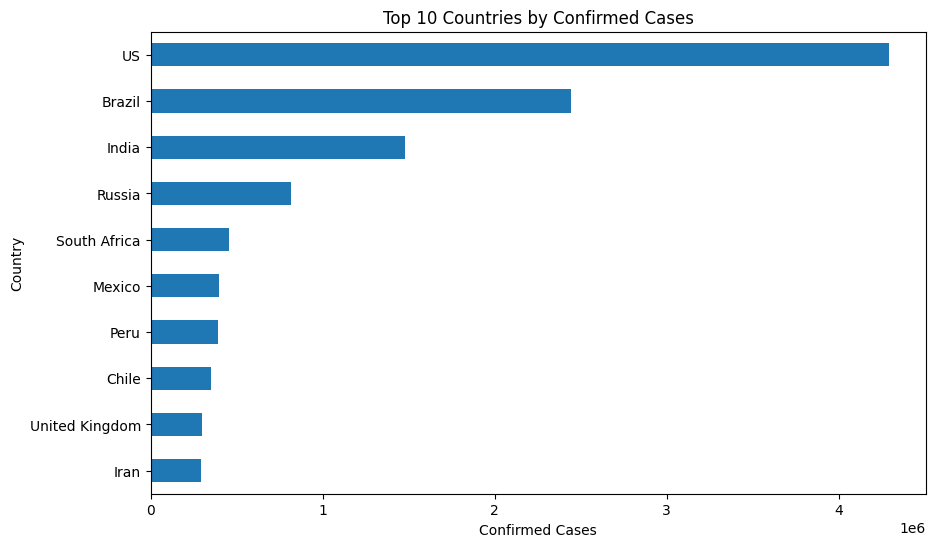

In [11]:
top10 = country_data.head(10)

top10['Confirmed'].sort_values().plot(
    kind='barh',
    figsize=(10,6)
)

plt.title("Top 10 Countries by Confirmed Cases")
plt.xlabel("Confirmed Cases")
plt.ylabel("Country")
plt.show()

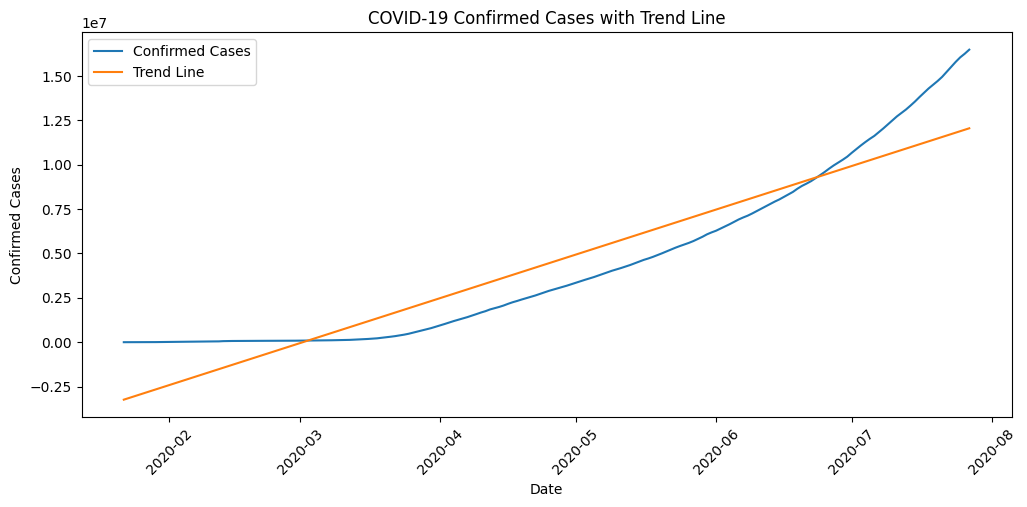

In [12]:
x = np.arange(len(daily))
y = daily['Confirmed'].values

trend = np.polyfit(x, y, 1)
trend_line = np.polyval(trend, x)

plt.figure(figsize=(12,5))

plt.plot(daily.index, y, label='Confirmed Cases')
plt.plot(daily.index, trend_line, label='Trend Line')

plt.title("COVID-19 Confirmed Cases with Trend Line")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.legend()
plt.xticks(rotation=45)
plt.show()